# Fisher matrix with the LISA response

This example computes a full Fisher matrix for an EMRI as seen through the LISA detector response, then plots the resulting parameter covariances as error ellipses. It covers:

1. Setting up a FEW waveform model (`FastSchwarzschildEccentricFlux`) wrapped in the LISA time-delay interferometry (TDI) response from `fastlisaresponse`, with the LISA noise PSDs of the A and E TDI channels from `lisatools`.
2. Computing the signal-to-noise ratio (SNR) of the source.
3. Computing the Fisher matrix over 11 parameters with stable numerical derivatives.
4. Inverting it to get the covariance matrix and the parameter uncertainties, and plotting the $1\sigma$, $2\sigma$ and $3\sigma$ ellipses.

On a CPU the notebook takes a few minutes; set `use_gpu = True` in the first cell to run on an NVIDIA GPU.

**Requirements:** `lisaanalysistools` and `fastlisaresponse`, for the LISA response and noise model (see the installation guide).

*Validated with LISAAnalysisTools-cuda12x v1.2.0 and fastlisaresponse v1.1.17.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import few
from few.waveform import FastSchwarzschildEccentricFlux
from fastlisaresponse import ResponseWrapper
from lisatools.detector import EqualArmlengthOrbits
from lisatools.sensitivity import get_sensitivity, A1TDISens, E1TDISens

from stableemrifisher.fisher import StableEMRIFisher
from stableemrifisher.utils.plot import plot_covariance_ellipses

use_gpu = False  # set to True to run on an NVIDIA GPU

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")

## Set up StableEMRIFisher

`StableEMRIFisher` takes the waveform and response *classes* together with their keyword arguments, rather than ready-made objects, so that it can build the waveform and its derivatives itself.

- **Waveform:** FEW's Schwarzschild eccentric flux model. `mode_selection_threshold` drops the harmonic modes that contribute less than this fraction of the total power.
- **Response:** first-generation TDI on equal-arm-length orbits, returning the A and E channels. `index_lambda` and `index_beta` tell the response which waveform arguments hold the sky position (`phiS` and `qS`); the first and last `t0` seconds of the signal are set to zero.
- **Noise:** the LISA PSD of each TDI channel, from `get_sensitivity` with the matching `sens_fn` (one dictionary of `noise_kwargs` per channel).

In [2]:
T = 0.01  # observation time, years
dt = 10.0  # sampling interval, seconds

ResponseWrapper_kwargs = dict(
    Tobs=T,
    dt=dt,
    index_lambda=8,  # position of phiS in the waveform arguments
    index_beta=7,  # position of qS in the waveform arguments
    t0=10000.0,  # seconds at each end of the signal where the response is unreliable
    remove_garbage="zero",  # zero the signal within t0 of each end
    flip_hx=True,  # FEW returns h+ - i hx
    is_ecliptic_latitude=False,  # qS is a polar angle, not a latitude
    orbits=EqualArmlengthOrbits(),
    order=20,  # order of the Lagrange interpolation of the time delays
    tdi="1st generation",
    tdi_chan="AE",
)

channels = [A1TDISens, E1TDISens]

sef = StableEMRIFisher(
    waveform_class=FastSchwarzschildEccentricFlux,
    waveform_class_kwargs=dict(
        inspiral_kwargs=dict(err=1e-11),  # trajectory integrator tolerance
        mode_selector_kwargs=dict(mode_selection_threshold=1e-5),
    ),
    ResponseWrapper=ResponseWrapper,
    ResponseWrapper_kwargs=ResponseWrapper_kwargs,
    noise_model=get_sensitivity,
    noise_kwargs=[{"sens_fn": channel} for channel in channels],
    channels=channels,
    deriv_type="stable",
    use_gpu=use_gpu,
)

## Source parameters and SNR

The source parameters are given as a dictionary, in the order FEW expects them. The Fisher matrix only approximates the posterior well at high SNR; SEF warns if the SNR is 20 or below.

In [3]:
wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=10.0,  # secondary mass, solar masses
    a=0.0,  # primary spin
    p0=9.5,  # initial semi-latus rectum
    e0=0.4,  # initial eccentricity
    xI0=1.0,  # cosine of the initial inclination
    dist=0.1,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # initial polar phase
    Phi_r0=0.0,  # initial radial phase
)

snr = sef.compute_snr(*wave_params.values(), dt=dt, T=T, use_gpu=use_gpu)
print(f"SNR = {snr:.1f}")

SNR = 61.8


## Compute the Fisher matrix

- `param_names`: the parameters in the Fisher matrix, in order. The spin `a` is left out because this Schwarzschild model has no spin, and `xI0` and `Phi_theta0` because the orbit is equatorial.
- `der_order`: the order of the finite-difference stencils.
- `Ndelta` and `delta_range`: for each parameter, SEF tries `Ndelta` step sizes (from `delta_range`, or a default grid for parameters not listed) and keeps the one where the diagonal Fisher element is most stable. `stability_plot=True` plots this search. The derivatives with respect to `dist` and the phases are analytic and need no step size.
- `stats_for_nerds=True` prints the step size chosen for each parameter and the relative error of its diagonal Fisher element.

Passing `deltas` instead (a dictionary with a step size for every parameter in `param_names`) skips the search and uses those step sizes.

Waveform Generated. SNR: 61.75618149641435
  m1         delta = 1.931e+01   relerr = 2.6e-13   (8 steps)             
  m2         delta = 1.931e-02   relerr = 8.2e-12   (8 steps)              
  p0         delta = 6.837e-04   relerr = 1.1e-07   (8 steps)              
  e0         delta = 1.491e-05   relerr = 4.8e-07   (8 steps)              
  dist       analytic derivative                                           
  qS         delta = 2.683e-08   relerr = 1.3e-06   (8 steps)              
  phiS       delta = 1.000e-09   relerr = 2.6e-06   (8 steps)                
  qK         delta = 1.931e-05   relerr = 1.1e-11   (8 steps)                
  phiK       delta = 1.931e-05   relerr = 7.1e-15   (8 steps)                
  Phi_phi0   analytic derivative                                             
  Phi_r0     analytic derivative                                             
Choosing step sizes: 100%|██████████| 64/64 [00:16<00:00,  3.96deriv/s]      


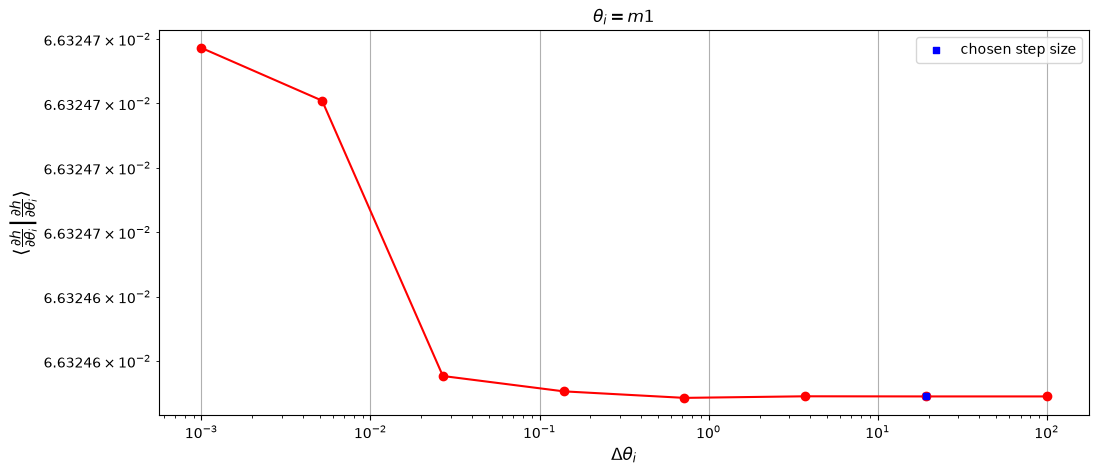

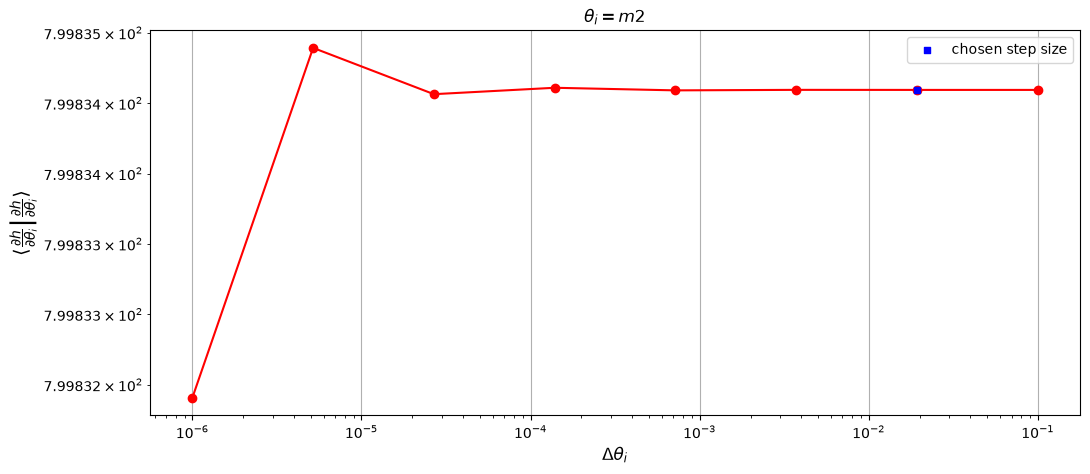

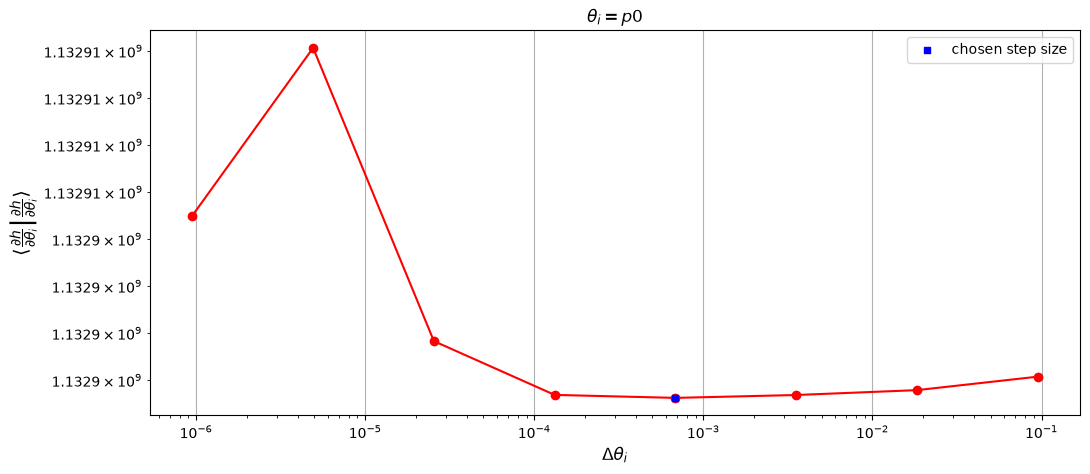

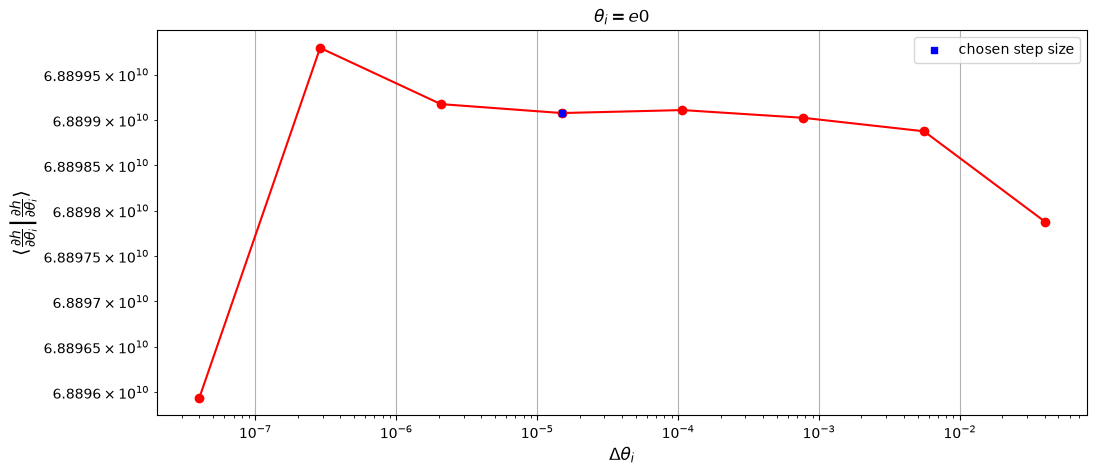

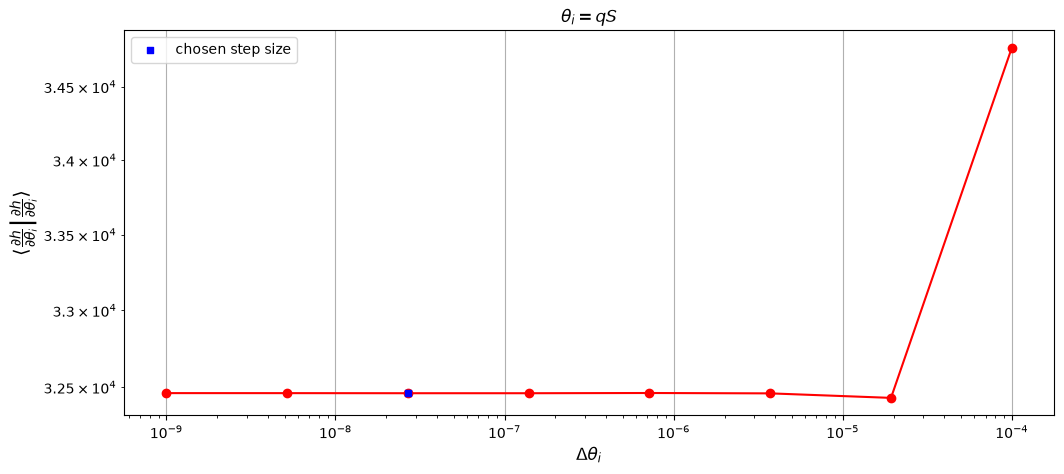

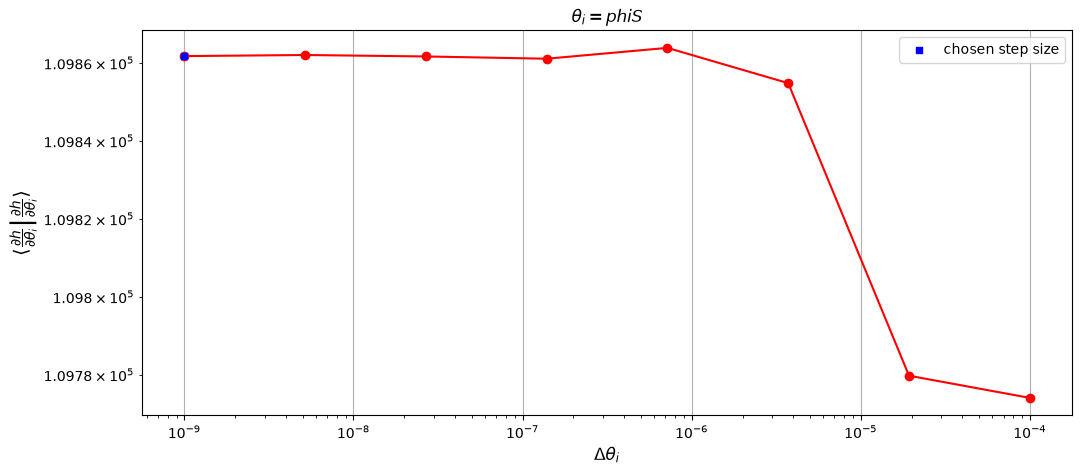

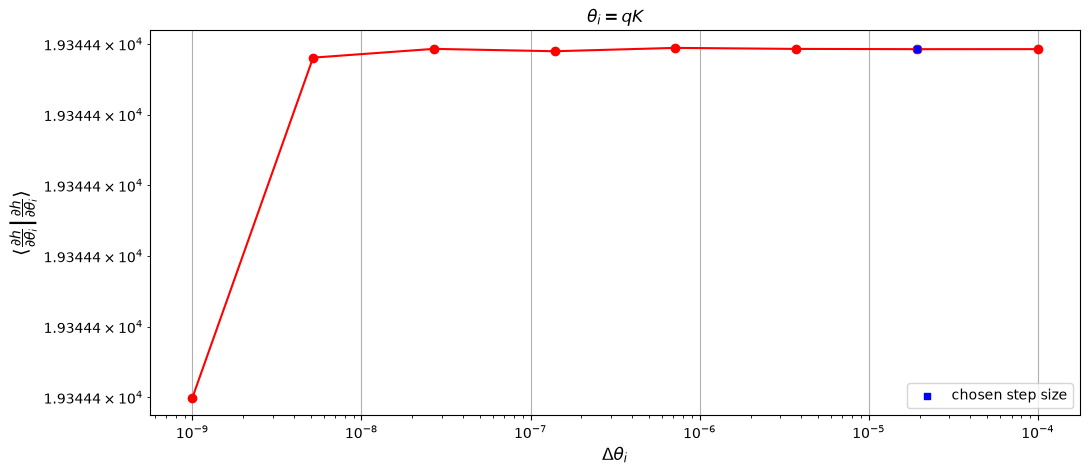

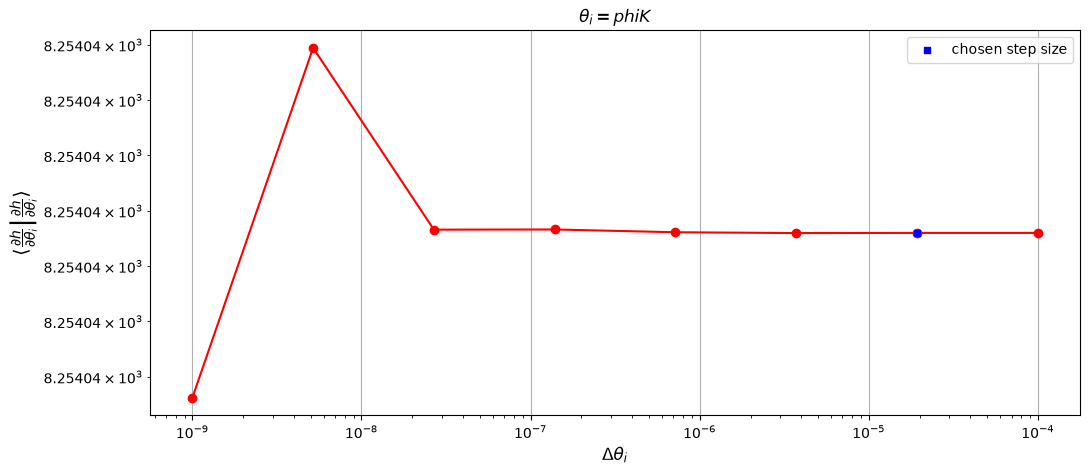

Computing Fisher   : 100%|██████████| 11/11 [00:02<00:00,  4.86deriv/s]          
Calculated Fisher is positive-definite.


In [4]:
param_names = ["m1", "m2", "p0", "e0", "dist", "qS", "phiS", "qK", "phiK", "Phi_phi0", "Phi_r0"]

Ndelta = 8
# trial step sizes for each parameter, from largest to smallest
delta_range = dict(
    m1=np.geomspace(1e-4 * wave_params["m1"], 1e-9 * wave_params["m1"], Ndelta),
    m2=np.geomspace(1e-2 * wave_params["m2"], 1e-7 * wave_params["m2"], Ndelta),
    p0=np.geomspace(1e-2 * wave_params["p0"], 1e-7 * wave_params["p0"], Ndelta),
    e0=np.geomspace(1e-1 * wave_params["e0"], 1e-7 * wave_params["e0"], Ndelta),
    qS=np.geomspace(1e-4, 1e-9, Ndelta),
    phiS=np.geomspace(1e-4, 1e-9, Ndelta),
    qK=np.geomspace(1e-4, 1e-9, Ndelta),
    phiK=np.geomspace(1e-4, 1e-9, Ndelta),
)

Fisher = sef(
    wave_params,
    param_names=param_names,
    der_order=4,
    Ndelta=Ndelta,
    delta_range=delta_range,
    stability_plot=True,
    stats_for_nerds=True,
)

## Parameter uncertainties

The inverse of the Fisher matrix approximates the covariance matrix of the parameter posterior; the square roots of its diagonal are the $1\sigma$ uncertainties.

In [5]:
covariance = np.linalg.inv(Fisher)
sigma = np.sqrt(np.diag(covariance))

for name, s in zip(param_names, sigma):
    print(f"{name:9s} = {wave_params[name]:.6g} +/- {s:.3g}")

m1        = 1e+06 +/- 3.51e+03
m2        = 10 +/- 0.286
p0        = 9.5 +/- 0.00184
e0        = 0.4 +/- 0.00322
dist      = 0.1 +/- 0.00615
qS        = 1.0472 +/- 0.0132
phiS      = 0.785398 +/- 0.0153
qK        = 0.523599 +/- 0.0338
phiK      = 0.392699 +/- 0.0611
Phi_phi0  = 1 +/- 0.0677
Phi_r0    = 0 +/- 0.0312


## Covariance ellipses

`plot_covariance_ellipses` draws the two-dimensional projections of the covariance matrix as a corner plot. It is called once per confidence level on the same axes, to overlay the $1\sigma$, $2\sigma$ and $3\sigma$ contours.

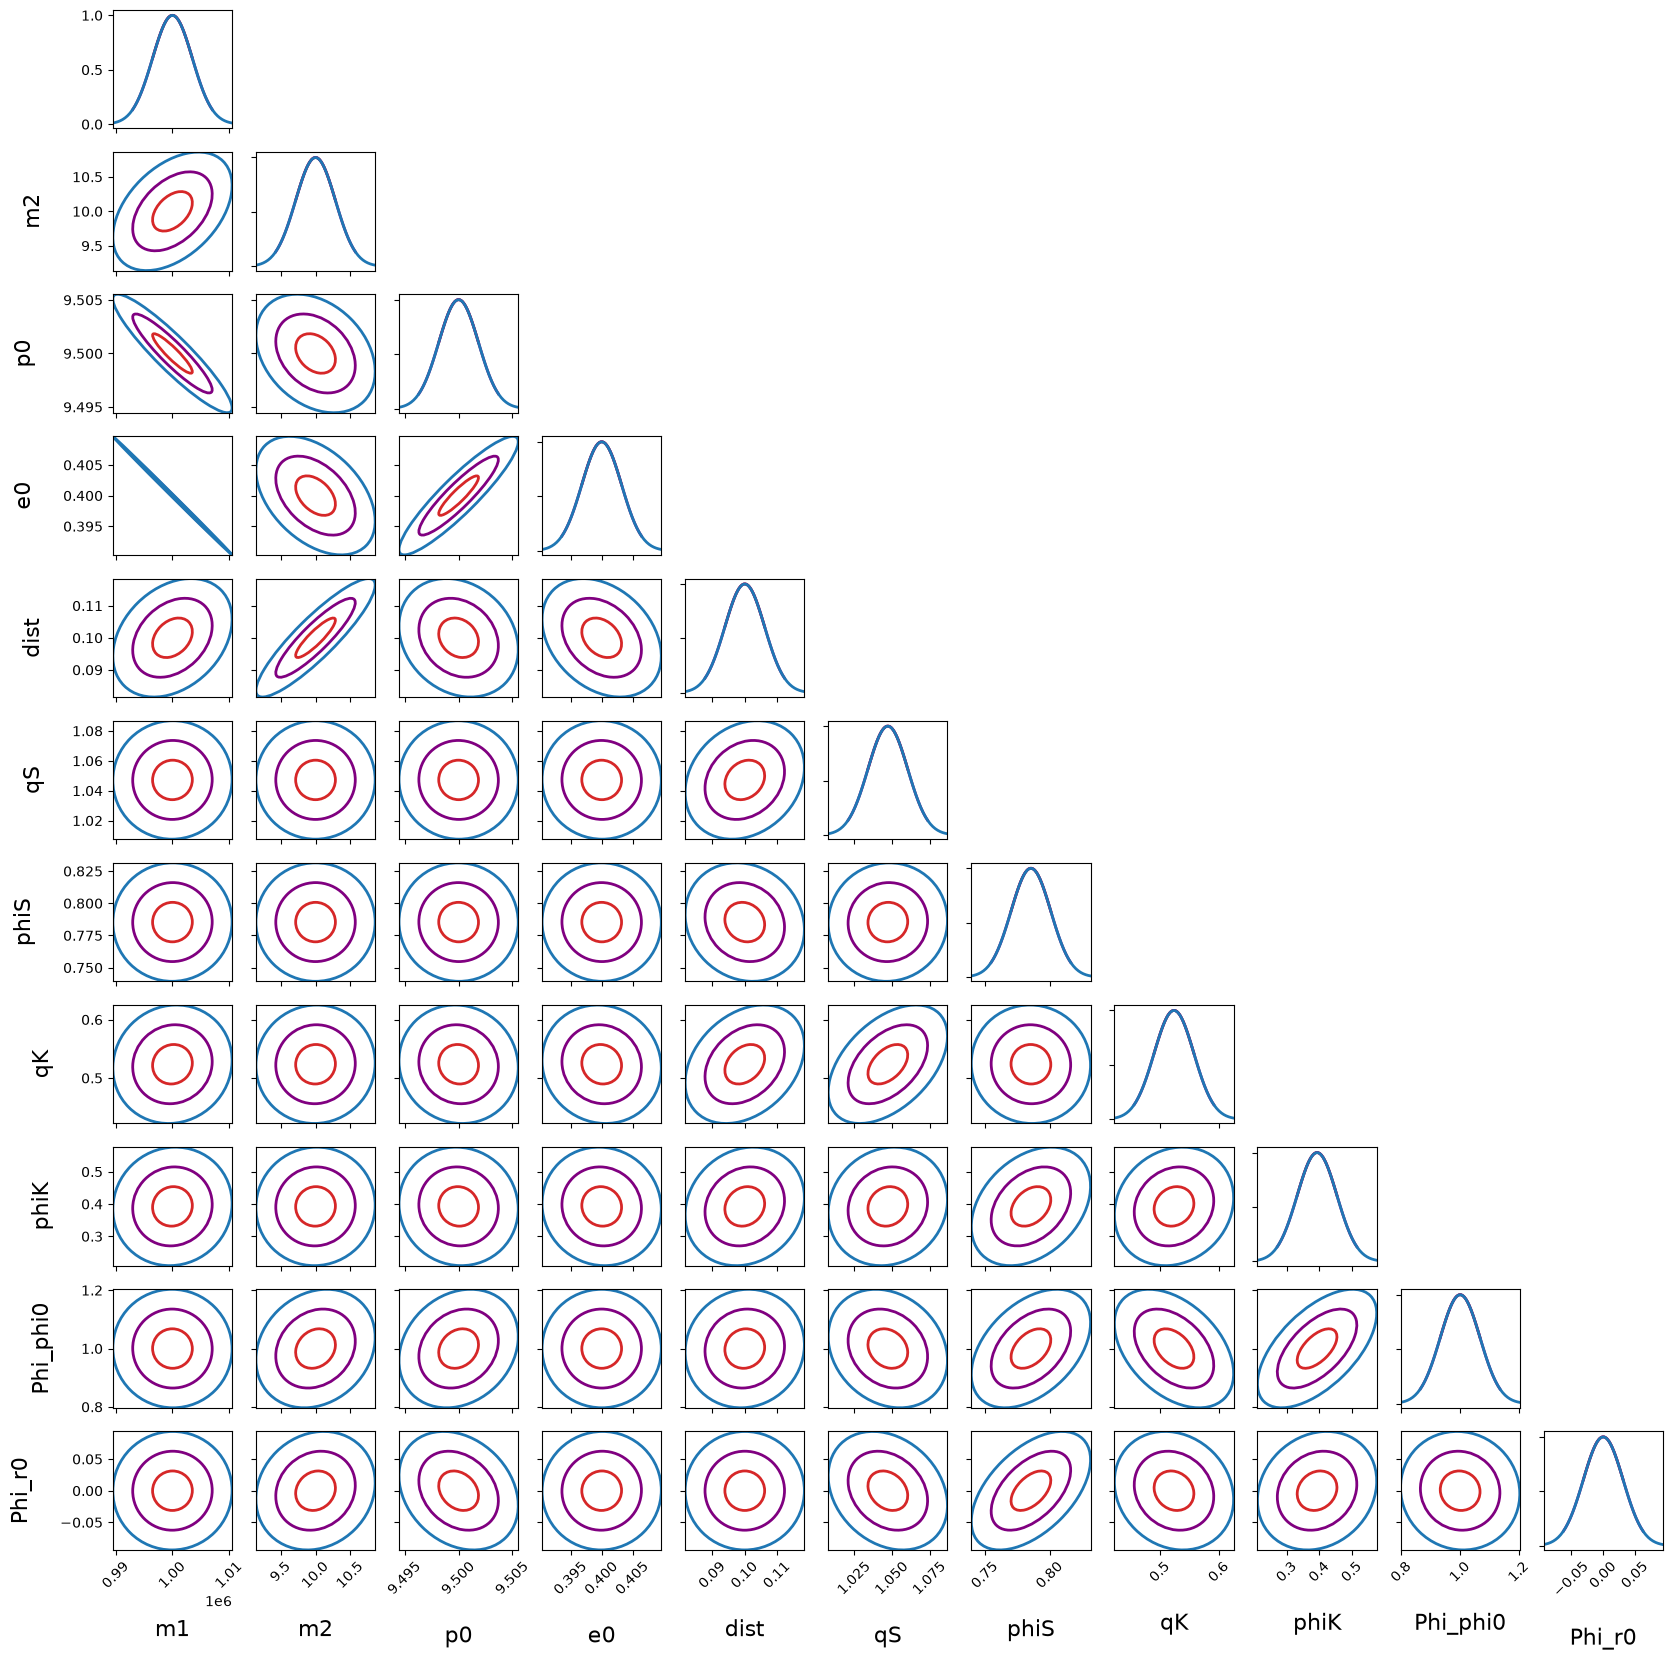

In [6]:
n = len(param_names)
fig, axs = plt.subplots(n, n, figsize=(20, 20))

for n_std, color in [(1, "tab:red"), (2, "purple"), (3, "tab:blue")]:
    plot_covariance_ellipses(
        covariance,
        param_names=param_names,
        wave_params=wave_params,
        fig=fig,
        axs=axs,
        ellipse_kwargs=dict(facecolor="none", edgecolor=color, lw=2, n_std=n_std),
        line_kwargs=dict(lw=2, color=color),
    )
plt.show()

## What this shows

A full Fisher matrix through the LISA response takes one `StableEMRIFisher` set-up and one call. To use your own noise model, see `custom_psd_tutorial.ipynb`; to check a Fisher estimate against the true likelihood, see `stable_derivative_one_param_with_response.ipynb`.